<a href="https://colab.research.google.com/github/PiKr-Salmon/CNN-Shape-Texture-/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import models
import kagglehub

# ใช้โมดูลสำหรับจัดการไฟล์บน Google Colab
from google.colab import files, drive

# Check Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

#print("\n--- Connecting to Google Drive for Permanent Storage ---")
#drive.mount('/content/drive')

# กำหนดพาธเซฟไฟล์ถาวรใน Google Drive
#DRIVE_SAVE_DIR = '/content/drive/MyDrive/CNN_Shape_VS_Texture/models'
#os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
#MODEL_FILENAME = 'STL10_3.pth'
#DRIVE_FILE_PATH = os.path.join(DRIVE_SAVE_DIR, MODEL_FILENAME)
#LOCAL_FILE_PATH = MODEL_FILENAME

# ==========================================
# 1. DEFINE CUSTOM TRANSFORMATIONS
# ==========================================

  ## Modifiable
class PatchShuffleTransform:
    """ทำลาย Global Shape แต่รักษา Local Texture โดยการสลับ Grid 4x4"""
    def __init__(self, grid_size=8):
        self.grid_size = grid_size
  ##

    def __call__(self, img):
        img_np = np.array(img)
        h, w, c = img_np.shape
        gh, gw = h // self.grid_size, w // self.grid_size

        patches = []
        for i in range(self.grid_size):
            for j in range(self.grid_size):
                patch = img_np[i*gh:(i+1)*gh, j*gw:(j+1)*gw, :]
                patches.append(patch)

        np.random.shuffle(patches)

        rows = []
        for i in range(self.grid_size):
            row = np.concatenate(patches[i*self.grid_size:(i+1)*self.grid_size], axis=1)
            rows.append(row)
        shuffled_img = np.concatenate(rows, axis=0)
        return transforms.functional.to_pil_image(shuffled_img)

## Modifiable
class EdgeExtractTransform:
    """ทำลาย Local Texture เหลือเพียง Global Shape (Sobel Contour)"""
    def __call__(self, img):
        img_np = np.array(img)
        gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
        sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
        sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
        edge = np.sqrt(sobelx**2 + sobely**2)
        edge = np.uint8(255 * edge / np.max(edge)) if np.max(edge) > 0 else np.uint8(edge)
        edge_3ch = cv2.cvtColor(edge, cv2.COLOR_GRAY2RGB)
        return transforms.functional.to_pil_image(edge_3ch)
##

#
#
#
def evaluate_model_debug(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            probs = torch.softmax(outputs, dim=1)

            # พิมพ์ดูค่าความมั่นใจสูงสุดของ Batch แรก
            print("Max Probs Sample:", probs.max(dim=1).values[:5].cpu().numpy())

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Total Evaluated Samples: {total}") # ต้องได้ 8000 ภาพสำหรับ STL-10 Test Set
    return 100.0 * correct / total

# ==========================================
# 2. DATASETS & LOADERS (STL-10)
# ==========================================

import os
from torchvision.transforms import ToTensor
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from PIL import Image
import kagglehub

# 1. ดาวน์โหลดชุดข้อมูลผ่าน KaggleHub
path = kagglehub.dataset_download("jessicali9530/stl10")
print("Path to dataset files:", path)
print("Files in Kaggle path:", os.listdir(path))

# 2. สร้าง Custom Dataset สำหรับโหลดรูปภาพจาก Folder โดยตรง
class FolderDataset(Dataset):
    def __init__(self, folder_path, transform=None):
        self.transform = transform
        self.image_paths = []

        # เดินสายสแกนหาไฟล์รูปภาพทั้งหมดที่อยู่ภายใต้โฟลเดอร์
        for root, _, files in os.walk(folder_path):
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff')):
                    self.image_paths.append(os.path.join(root, file))

        print(f"Loaded {len(self.image_paths):,} images from {os.path.basename(folder_path)}")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, 0  # ส่งค่าเลเบลสมมติ (0) กลับไปเพื่อให้คงฟอร์แมตดั้งเดิม

## Modifiable
# สร้าง Transforms สำหรับแต่ละแบบ
transform_orig = transforms.Compose([
    transforms.Resize((96, 96)),

    #transforms.ColorJitter(brightness=0.8, contrast=0.8, saturation=0.8, hue=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_patch = transforms.Compose([
    transforms.Resize((96, 96)),

    #transforms.ColorJitter(brightness=0.8, contrast=0.8, saturation=0.8, hue=0.5),
    PatchShuffleTransform(grid_size=8),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_edge = transforms.Compose([
    transforms.Resize((96, 96)),

    #transforms.ColorJitter(brightness=0.8, contrast=0.8, saturation=0.8, hue=0.5),
    EdgeExtractTransform(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
##

print("Downloading STL-10 Dataset (BSD-3 Clause)...")
# 4. โหลดข้อมูลจริงผ่าน Folder

train_set = FolderDataset(
    folder_path=os.path.join(path, "train_images"),
    transform=transform_orig
)

test_set_orig = FolderDataset(
    folder_path=os.path.join(path, "test_images"),
    transform=ToTensor()
)

test_set_patch = FolderDataset(
    folder_path=os.path.join(path, "test_images"),
    transform=transform_patch
)

test_set_edge = FolderDataset(
    folder_path=os.path.join(path, "test_images"),
    transform=transform_edge
)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True, num_workers=2)
test_loader_orig = torch.utils.data.DataLoader(test_set_orig, batch_size=64, shuffle=False, num_workers=2)
test_loader_patch = torch.utils.data.DataLoader(test_set_patch, batch_size=64, shuffle=False, num_workers=2)
test_loader_edge = torch.utils.data.DataLoader(test_set_edge, batch_size=64, shuffle=False, num_workers=2)

Using device: cpu

--- Connecting to Google Drive for Permanent Storage ---
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using Colab cache for faster access to the 'stl10' dataset.
Path to dataset files: /kaggle/input/stl10
Files in Kaggle path: ['unlabeled_images', 'train_images', 'test_images']
Loaded 5,000 images from train_images
Loaded 8,000 images from test_images
Loaded 8,000 images from test_images
Loaded 8,000 images from test_images


In [13]:
# ==========================================
# 3. EVALUATION FUNCTION
# ==========================================

def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100.0 * correct / total


# ==========================================
# 4. CONDITION A: PRE-TRAINED BASELINE
# ==========================================

## Modifiable
print("\n--- Evaluating Condition A: Pre-trained Baseline ResNet-18 ---")
model_a = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
##
model_a.fc = nn.Linear(model_a.fc.in_features, 10)
model_a = model_a.to(device)

acc_orig_a = evaluate_model(model_a, test_loader_orig)
acc_patch_a = evaluate_model(model_a, test_loader_patch)
acc_edge_a = evaluate_model(model_a, test_loader_edge)

print(f"Condition A - Original Accuracy: {acc_orig_a:.2f}%")
print(f"Condition A - Patch-Shuffled (Texture Only) Accuracy: {acc_patch_a:.2f}%")
print(f"Condition A - Edge-Extracted (Shape Only) Accuracy: {acc_edge_a:.2f}%")

# ==========================================
# 5. CONDITION B: FINE-TUNING MODEL
# ==========================================

## Modifiable
print("\n--- Training Condition B: Fine-tuning ResNet-18 ---")
model_b = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
##
model_b.fc = nn.Linear(model_b.fc.in_features, 10)
model_b = model_b.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_b.parameters(), lr=1e-4)

# Fine-tune loop (4 Epochs)
model_b.train()
for epoch in range(4):
    running_loss = 0.0
    print(f"Epoch {epoch+1}")
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model_b(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f" Loss: {running_loss/len(train_loader):.4f}")

# วัดค่าความแม่นยำหลัง Fine-tune ทันที
acc_orig_b = evaluate_model(model_b, test_loader_orig)
acc_patch_b = evaluate_model(model_b, test_loader_patch)
acc_edge_b = evaluate_model(model_b, test_loader_edge)

#evaluate_model_debug(model_b, test_loader_orig)
#evaluate_model_debug(model_b, test_loader_patch)
#evaluate_model_debug(model_b, test_loader_edge)

print(f"\nCondition B (Before Saving) - Original Accuracy: {acc_orig_b:.2f}%")
print(f"Condition B (Before Saving) - Patch-Shuffled Accuracy: {acc_patch_b:.2f}%")
print(f"Condition B (Before Saving) - Edge-Extracted Accuracy: {acc_edge_b:.2f}%")

# ==========================================
# 6. SAVE MODEL WEIGHTS
# ==========================================

# 1. บันทึกถาวรลง Google Drive
#print(f"\n[1/2] Saving model weights permanently to Google Drive: '{DRIVE_FILE_PATH}'...")
#torch.save(model_b.state_dict(), DRIVE_FILE_PATH)

# 2. บันทึกลง Local Colab Session และดาวน์โหลดลงเครื่องคอมพิวเตอร์
#print(f"[2/2] Saving local copy to '{LOCAL_FILE_PATH}' and triggering browser download...")
#torch.save(model_b.state_dict(), LOCAL_FILE_PATH)
#files.download(LOCAL_FILE_PATH)


--- Evaluating Condition A: Pre-trained Baseline ResNet-18 ---
Condition A - Original Accuracy: 10.81%
Condition A - Patch-Shuffled (Texture Only) Accuracy: 0.69%
Condition A - Edge-Extracted (Shape Only) Accuracy: 0.79%

--- Training Condition B: Fine-tuning ResNet-18 ---
Epoch 1
 Loss: 0.8017
Epoch 2
 Loss: 0.0323
Epoch 3
 Loss: 0.0145
Epoch 4
 Loss: 0.0089

Condition B (Before Saving) - Original Accuracy: 100.00%
Condition B (Before Saving) - Patch-Shuffled Accuracy: 100.00%
Condition B (Before Saving) - Edge-Extracted Accuracy: 100.00%

[1/2] Saving model weights permanently to Google Drive: '/content/drive/MyDrive/CNN_Shape_VS_Texture/models/STL10_3.pth'...
[2/2] Saving local copy to 'STL10_3.pth' and triggering browser download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


   SELECT MODEL FILE TO LOAD & TEST ACCURACY
กรุณากดปุ่ม 'Choose Files' ด้านล่าง เพื่อเลือกไฟล์น้ำหนัก (.pth) จากเครื่องของคุณ


Saving STL10_3.pth to STL10_3 (1).pth

กำลังโหลดไฟล์โมเดลที่เลือก: 'STL10_3 (1).pth'...

--- Evaluating Accuracy from Selected Model File ---
Loaded Model - Original Accuracy: 10.81%
Loaded Model - Patch-Shuffled Accuracy: 0.69%
Loaded Model - Edge-Extracted Accuracy: 0.79%
Loaded Model - Original Accuracy: 100.00%
Loaded Model - Patch-Shuffled Accuracy: 100.00%
Loaded Model - Edge-Extracted Accuracy: 100.00%


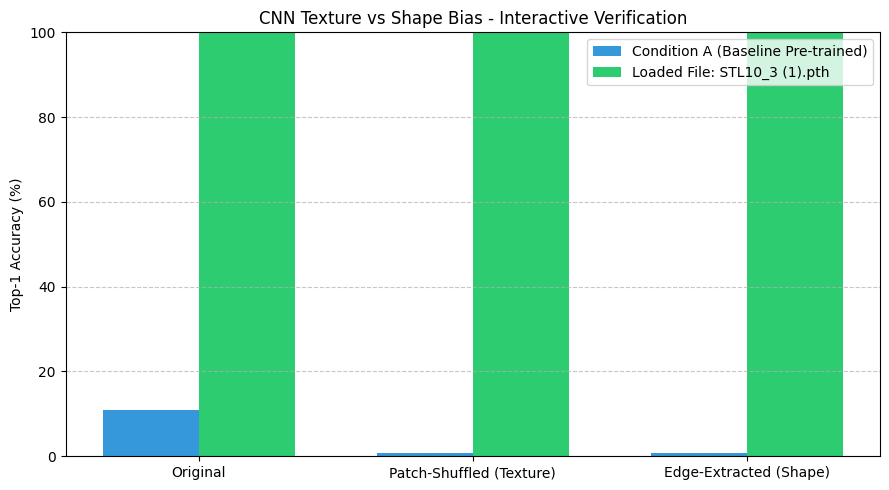

In [14]:
from pickle import STOP
from google.colab import files, drive
# ==========================================
# 7. INTERACTIVE FILE SELECTION & VERIFICATION
# ==========================================

print("\n==================================================")
print("   SELECT MODEL FILE TO LOAD & TEST ACCURACY")
print("==================================================")
print("กรุณากดปุ่ม 'Choose Files' ด้านล่าง เพื่อเลือกไฟล์น้ำหนัก (.pth) จากเครื่องของคุณ")

# เปิด Pop-up UI ให้ผู้ใช้เลือกไฟล์จากเครื่องคอมพิวเตอร์
uploaded = files.upload()

if len(uploaded) > 0:
    # ดึงชื่อไฟล์ที่ผู้ใช้เลือกขึ้นมา
    selected_filename = list(uploaded.keys())[0]
    print(f"\nกำลังโหลดไฟล์โมเดลที่เลือก: '{selected_filename}'...")

    # สร้างโครงสร้างโมเดลใหม่ขึ้นมาเปล่าๆ
    interactive_model = models.resnet18()
    interactive_model.fc = nn.Linear(interactive_model.fc.in_features, 10)

    # โหลดค่าน้ำหนักจากไฟล์ที่ผู้ใช้เลือก
    interactive_model.load_state_dict(torch.load(selected_filename, map_location=device))
    interactive_model = interactive_model.to(device)
    interactive_model.eval()

    # ทดสอบประสิทธิภาพโมเดลที่โหลดขึ้นมาจากไฟล์ที่เลือก
    print("\n--- Evaluating Accuracy from Selected Model File ---")
    acc_orig_sel = evaluate_model(interactive_model, test_loader_orig)
    acc_patch_sel = evaluate_model(interactive_model, test_loader_patch)
    acc_edge_sel = evaluate_model(interactive_model, test_loader_edge)

    print(f"Loaded Model - Original Accuracy: {acc_orig_a:.2f}%")
    print(f"Loaded Model - Patch-Shuffled Accuracy: {acc_patch_a:.2f}%")
    print(f"Loaded Model - Edge-Extracted Accuracy: {acc_edge_a:.2f}%")

    print(f"Loaded Model - Original Accuracy: {acc_orig_sel:.2f}%")
    print(f"Loaded Model - Patch-Shuffled Accuracy: {acc_patch_sel:.2f}%")
    print(f"Loaded Model - Edge-Extracted Accuracy: {acc_edge_sel:.2f}%")

    # พล็อตเปรียบเทียบผลลัพธ์
    labels = ['Original', 'Patch-Shuffled (Texture)', 'Edge-Extracted (Shape)']
    cond_a = [acc_orig_a, acc_patch_a, acc_edge_a]
    cond_selected = [acc_orig_sel, acc_patch_sel, acc_edge_sel]

    x = np.arange(len(labels))
    width = 0.35

    fig, ax = plt.subplots(figsize=(9, 5))
    rects1 = ax.bar(x - width/2, cond_a, width, label='Condition A (Baseline Pre-trained)', color='#3498db')
    rects2 = ax.bar(x + width/2, cond_selected, width, label=f'Loaded File: {selected_filename}', color='#2ecc71')

    ax.set_ylabel('Top-1 Accuracy (%)')
    ax.set_title('CNN Texture vs Shape Bias - Interactive Verification')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, 100)
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

else:
    print("No file was uploaded.")